# **PRAKTIKUM 1**

**Langkah 0 - Persiapan Data**

In [1]:
import os
import warnings
os.environ['OMP_NUM_THREADS'] = '1'
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

df = pd.read_csv('../Data/jakarta_house.csv')
df['land_area'] = df['land_area'].fillna(df['land_area'].mean())
df['building_area'] = df['building_area'].fillna(df['building_area'].mean())

df.head()

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


**Langkah 1 - Seleksi Fitur**

In [2]:
X = df[['land_area', 'building_area']]
y = df['city']

print(X.head())

   land_area  building_area
0      250.0          350.0
1      100.0          225.0
2       60.0          140.0
3       60.0          120.0
4       56.0          108.0


**Langkah 2 - Visualisasi Data Awal**

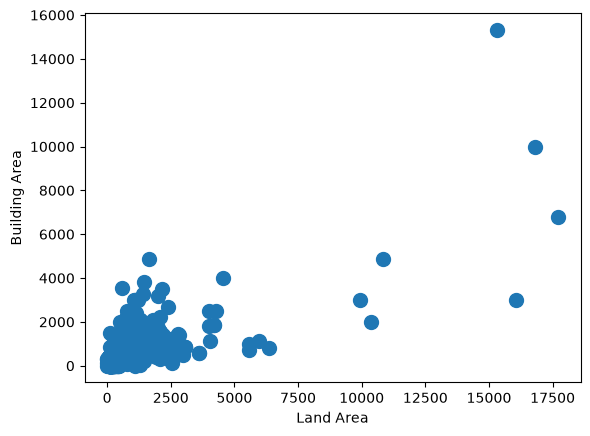

In [3]:
# Plot Data
# Plot cluster berdasarkan Land Area dan Building Area

plt.scatter(X.iloc[:, 0], X.iloc[:, 1], s = 100)
plt.xlabel("Land Area")
plt.ylabel("Building Area")
plt.show()

**Langkah 3 - Membuat Model K-Means**

In [4]:
# Buat Model KMeans
# Kali ini kita coba menggunakan k=2

from sklearn.cluster import KMeans

# Inisiasi obyek KMeans
cl_kmeans = KMeans(n_clusters=2, random_state=42)

# Fit dan predict model
y_kmeans = cl_kmeans.fit_predict(X)

**Langkah 4 - Visualisasi Hasil Clustering**

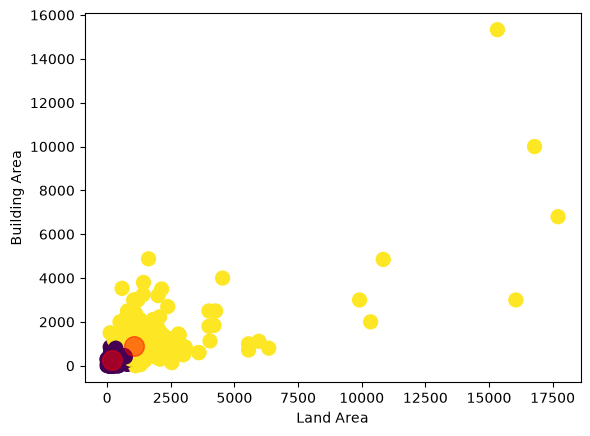

In [5]:
# Plot hasi cluster berdasarkan Land Area dan Building Area
plt.scatter(X.iloc[:, 0], X.iloc[:, 1], cmap='viridis', s = 100, c=y_kmeans)

# Plot centroid
centers = cl_kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)
plt.xlabel("Land Area")
plt.ylabel("Building Area")
plt.show()

**Langkah 5 - Menghitung Nilai SSE**

In [6]:
# Cek Nilai SSE
print(f'Nilai SSE: {cl_kmeans.inertia_}')

Nilai SSE: 2626781019.2230725


**Langkah 6 - Implementasi Metode Elbow**

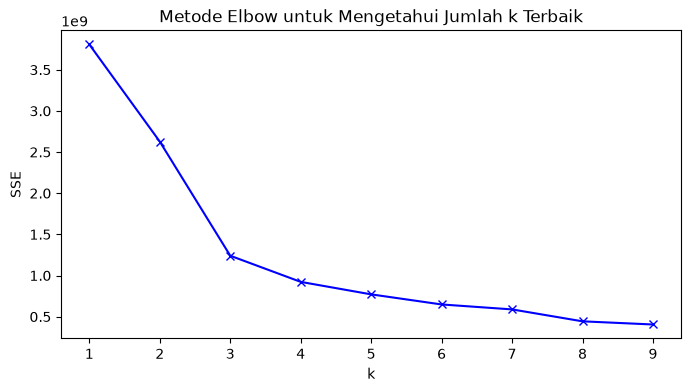

In [7]:
# Implementasi Metode Elbow

# List nilai SSE
sse = []

# Cari k terbaik dari 1-10
K = range(1,10)

# Cek nilai SSE setiap k
for k in K:
    kmeanModel = KMeans(n_clusters=k, random_state=42)
    kmeanModel.fit(X)
    sse.append(kmeanModel.inertia_)

# Plotting the distortions
plt.figure(figsize=(8,4))
plt.plot(K, sse, "bx-")
plt.xlabel("k")
plt.ylabel("SSE")
plt.title("Metode Elbow untuk Mengetahui Jumlah k Terbaik")
plt.show()

**Langkah 7 - Menampilkan Nilai SSE Setiap k**

In [8]:
# Cek Nilai SSE setiap k
for idx, sse_val in enumerate(sse, start=1):
    print(f'k={idx}; SSE={sse_val}')

k=1; SSE=3806844364.8138433
k=2; SSE=2626781019.2230725
k=3; SSE=1240272190.1390843
k=4; SSE=922564574.3076622
k=5; SSE=770805432.9772239
k=6; SSE=648201884.9629385
k=7; SSE=588056653.1525451
k=8; SSE=443161156.12157226
k=9; SSE=404755689.0382382
